# How have the cities changed, and what did it do to their heat?

For each of the 281 cities (Member 1's ~7.7 km cells) and each year 2016–2025, `urbanheat change` (Earth Engine) measures:

- **green, built-up, water and bare area** (ha), from Dynamic World (10 m; each pixel's most frequent class of the year)
- **hot-season land surface temperature** (Landsat 8/9, median of clear pixels), for the city's built-up pixels and for
  a **rural ring** 1–6 km around it. The hot season is each city's 3 warmest months.
- **surface urban heat island (SUHI)** = built-up LST − rural LST

`urbanheat change --transitions` then compares the first and last three years pixel by pixel: how much more did
pixels that changed (e.g. green → built) warm than pixels that stayed the same in the same city? That
difference-in-differences cancels the weather and the regional climate trend.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from urbanheat.config import load_config

cfg = load_config()
root = Path(cfg["data"]["derived_dir"]) / "change"
t = pd.read_csv(root / "cell_year.csv")
t["area"] = t[["green", "built", "water", "bare"]].sum(axis=1)
for c in ["green", "built", "water"]:
    t[c + "_pct"] = t[c] / t.area * 100
plt.rcParams["figure.dpi"] = 90
print(f"{t.cell_id.nunique()} cities x {t.year.nunique()} years = {len(t)} rows; "
      f"{int(t.lst_built_c.isna().sum())} city-years without a clear hot-season Landsat scene")

281 cities x 10 years = 2810 rows; 16 city-years without a clear hot-season Landsat scene


## Land-cover change: first three years vs last three years

In [2]:
early, late = t[t.year <= 2018].groupby("cell_id"), t[t.year >= 2023].groupby("cell_id")
cols = ["green", "built", "water", "green_pct", "built_pct", "water_pct", "suhi_c"]
d = late[cols].mean() - early[cols].mean()
d["climate_group"] = t.groupby("cell_id").climate_group.first()
print("all 281 cities together (ha): green {:+,.0f}  built {:+,.0f}  water {:+,.0f}".format(d.green.sum(), d.built.sum(), d.water.sum()))
print(f"cities that lost green worth > 5 % of their area: {(d.green_pct < -5).sum()}; gained built > 5 %: {(d.built_pct > 5).sum()}")
d.groupby("climate_group")[["green_pct", "built_pct", "water_pct"]].median().round(2).rename(
    columns=lambda c: "median change, % of city area: " + c.replace("_pct", ""))

all 281 cities together (ha): green -78,910  built +92,587  water -1,695
cities that lost green worth > 5 % of their area: 120; gained built > 5 %: 133


,"median change, % of city area: green","median change, % of city area: built","median change, % of city area: water"
climate_group,,,
arid,-2.26,3.47,-0.01
cold,-1.95,2.16,-0.05
temperate,-0.84,1.08,-0.02
tropical,-5.54,5.78,-0.02


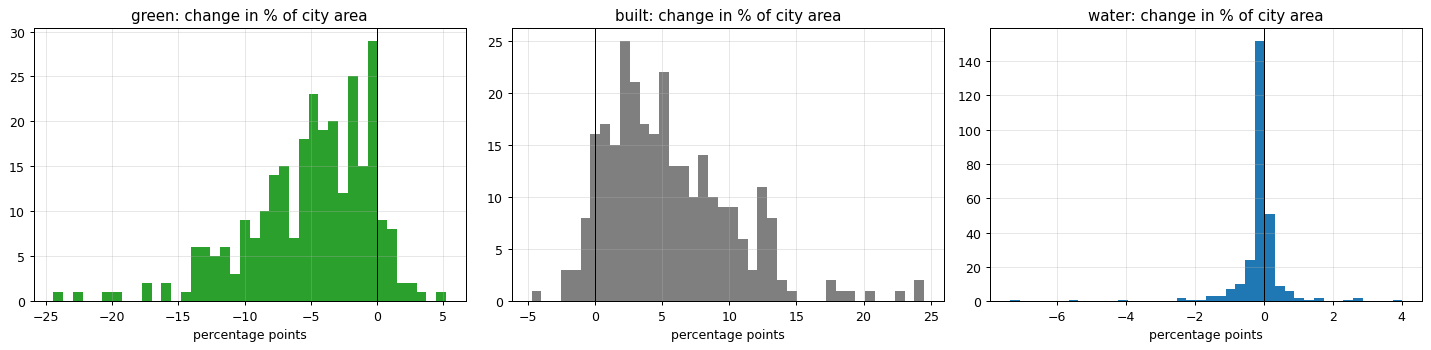

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c, col in zip(ax, ["green_pct", "built_pct", "water_pct"], ["tab:green", "tab:gray", "tab:blue"]):
    a.hist(d[c], bins=40, color=col); a.axvline(0, color="k", lw=.8)
    a.set_title(f"{c.replace('_pct', '')}: change in % of city area"); a.set_xlabel("percentage points"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Cities with the largest change

In [4]:
idx = pd.read_csv(cfg["data"]["index_file"])
names = idx.groupby("cell_id")[["cell_lon", "cell_lat"]].first()
top = d.sort_values("green_pct").head(10)[["climate_group", "green", "green_pct", "built", "built_pct", "water_pct"]]
top.join(names).round(1)

,climate_group,green,green_pct,built,built_pct,water_pct,cell_lon,cell_lat
cell_id,,,,,,,,
39.205_-15.105,tropical,-1444.8,-24.4,1449.1,24.5,-0.0,39.2,-15.1
32.975_-2.575,tropical,-1325.2,-22.4,1326.6,22.5,0.0,33.0,-2.6
110.395_-7.685,tropical,-1199.1,-20.3,1200.2,20.3,-0.0,110.4,-7.7
30.245_1.555,tropical,-1154.2,-19.5,1132.5,19.2,0.0,30.2,1.6
32.485_-25.815,arid,-1051.1,-17.8,1051.4,17.8,-0.0,32.5,-25.8
3.855_7.295,tropical,-1012.9,-17.1,1430.0,24.2,-0.2,3.9,7.3
8.545_11.915,tropical,-949.9,-16.1,671.6,11.4,0.1,8.5,11.9
8.475_12.055,tropical,-931.2,-15.8,843.6,14.3,-0.0,8.5,12.1
29.755_-2.575,tropical,-833.0,-14.1,833.5,14.1,-0.0,29.8,-2.6


### Year by year: two Indian cities with multi-year data (Pune; a cell near Mumbai)

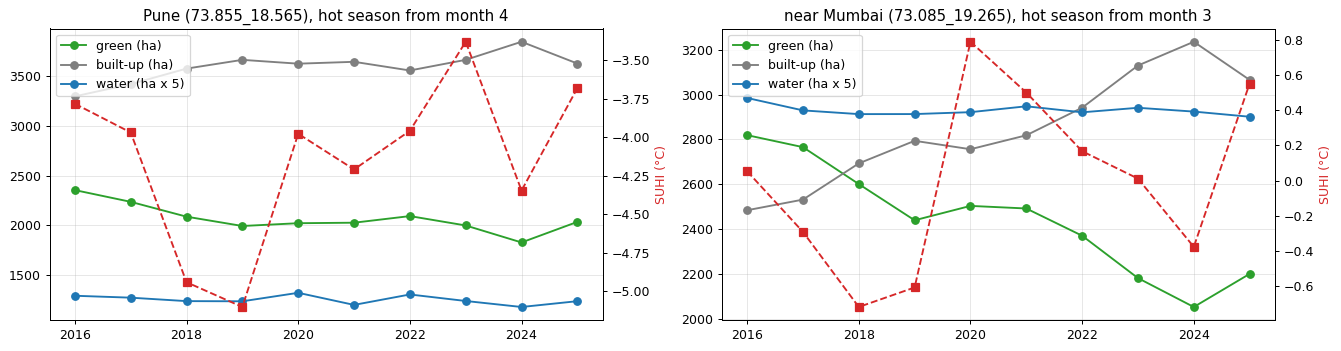

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, cid, name in [(ax[0], "73.855_18.565", "Pune"), (ax[1], "73.085_19.265", "near Mumbai")]:
    s = t[t.cell_id == cid].sort_values("year")
    a.plot(s.year, s.green, "o-", color="tab:green", label="green (ha)")
    a.plot(s.year, s.built, "o-", color="tab:gray", label="built-up (ha)")
    a.plot(s.year, s.water * 5, "o-", color="tab:blue", label="water (ha x 5)")
    a2 = a.twinx(); a2.plot(s.year, s.suhi_c, "s--", color="tab:red", label="SUHI (°C)"); a2.set_ylabel("SUHI (°C)", color="tab:red")
    a.set_title(f"{name} ({cid}), hot season from month {int(s.hot_season_start_month.iloc[0])}"); a.legend(loc="upper left"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## The surface urban heat island

Positive = built-up areas are hotter than the countryside around them. In dry seasons, bare or dry farmland
around semi-arid cities can be hotter than the city (a *surface cool island*), which is why some values are negative.

C:\Users\Sebin George\AppData\Local\Temp\ipykernel_26604\980083655.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([t[t.climate_group == g].suhi_c.dropna() for g in groups], labels=groups, showfliers=False)


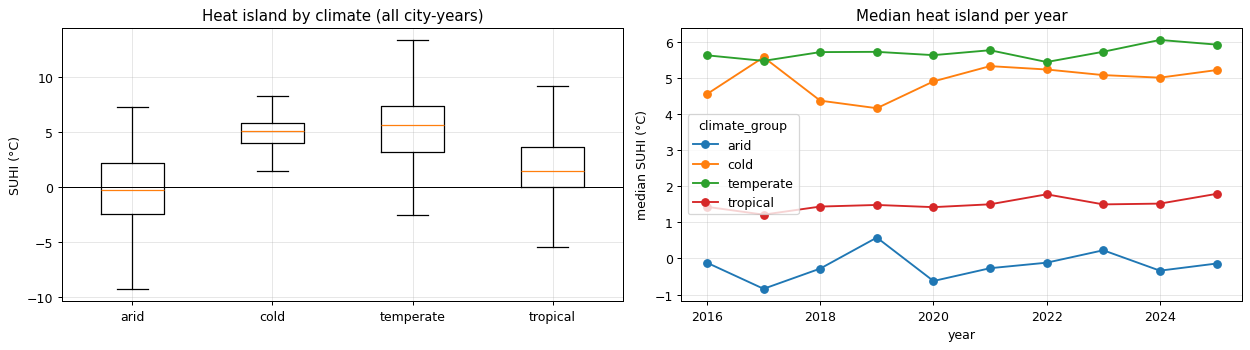

,count,25%,50%,75%
climate_group,,,,
arid,330.0,-2.38,-0.20,2.26
cold,150.0,4.00,5.08,5.87
temperate,389.0,3.26,5.70,7.43
tropical,1925.0,-0.00,1.50,3.70


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
groups = sorted(t.climate_group.unique())
ax[0].boxplot([t[t.climate_group == g].suhi_c.dropna() for g in groups], labels=groups, showfliers=False)
ax[0].axhline(0, color="k", lw=.8); ax[0].set_ylabel("SUHI (°C)"); ax[0].set_title("Heat island by climate (all city-years)"); ax[0].grid(alpha=.3)
trend = t.groupby(["year", "climate_group"]).suhi_c.median().unstack()
trend.plot(ax=ax[1], marker="o"); ax[1].set_ylabel("median SUHI (°C)"); ax[1].set_title("Median heat island per year"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
t.groupby("climate_group").suhi_c.describe()[["count", "25%", "50%", "75%"]].round(2)

## Did losing green space make places hotter?

**City-wide numbers are the wrong test.** The change in a city's heat island hardly correlates with its change in
built-up area: adding new built pixels barely moves the *average* built-up temperature, the rural ring urbanises
too, and year-to-year noise (a few Landsat scenes per season) is larger than a city-wide effect.

In [7]:
ok = d.suhi_c.notna()
print("correlation across cities, change in SUHI vs change in built-up %:", round(np.corrcoef(d.built_pct[ok], d.suhi_c[ok])[0, 1], 2))

correlation across cities, change in SUHI vs change in built-up %: -0.02


**The pixel-level test**: inside each city, compare the hot-season temperature change (2023–25 minus 2016–18) of
pixels that changed land cover with pixels that stayed the same. Weather and the regional climate trend affect both
and cancel out.

In [8]:
tr = pd.read_csv(root / "transitions.csv")
def did(a, b, frame=tr, min_n=100):
    ok = (frame[f"n_{a}"] >= min_n) & (frame[f"n_{b}"] >= min_n)
    return (frame[f"dlst_{a}"] - frame[f"dlst_{b}"])[ok]

rng = np.random.default_rng(0)
rows = []
for a, b, label in [("green_to_built", "green_stable", "green -> built"), ("built_to_green", "built_stable", "built -> green"),
                    ("water_to_other", "water_stable", "water -> other")]:
    x = did(a, b)
    ci = np.percentile([np.median(rng.choice(x, len(x))) for _ in range(2000)], [2.5, 97.5])
    rows.append(dict(change=label, compared_with=b.replace("_", " "), cities=len(x), extra_warming_c_median=x.median(),
                     ci_low=ci[0], ci_high=ci[1], share_of_cities_warmer=(x > 0).mean()))
res = pd.DataFrame(rows)
res.round(2)

,change,compared_with,cities,extra_warming_c_median,ci_low,ci_high,share_of_cities_warmer
0,green -> built,green stable,280,0.36,0.29,0.44,0.72
1,built -> green,built stable,275,-0.42,-0.49,-0.38,0.21
2,water -> other,water stable,139,0.54,0.32,0.74,0.74


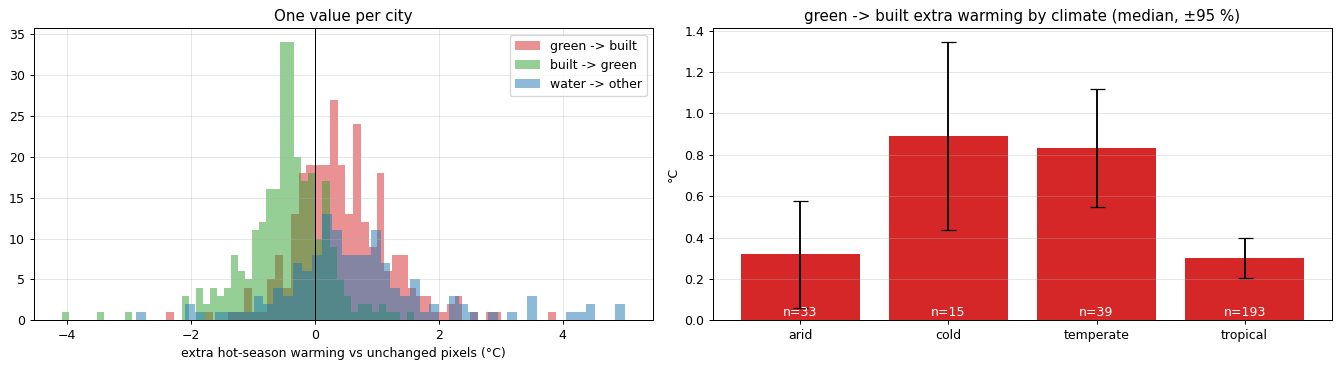

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for (a, b, label), col in zip([("green_to_built", "green_stable", "green -> built"), ("built_to_green", "built_stable", "built -> green"),
                               ("water_to_other", "water_stable", "water -> other")], ["tab:red", "tab:green", "tab:blue"]):
    ax[0].hist(did(a, b).clip(-5, 5), bins=50, alpha=.5, color=col, label=label)
ax[0].axvline(0, color="k", lw=.8); ax[0].set_xlabel("extra hot-season warming vs unchanged pixels (°C)")
ax[0].set_title("One value per city"); ax[0].legend(); ax[0].grid(alpha=.3)
tr["did_gb"] = tr.dlst_green_to_built - tr.dlst_green_stable
ok = (tr.n_green_to_built >= 100) & (tr.n_green_stable >= 100)
g = tr[ok].groupby("climate_group").did_gb
ax[1].bar(g.median().index, g.median(), yerr=g.sem() * 1.96, capsize=6, color="tab:red")
for i, (k, n) in enumerate(g.count().items()):
    ax[1].text(i, 0.02, f"n={n}", ha="center", color="w")
ax[1].set_ylabel("°C"); ax[1].set_title("green -> built extra warming by climate (median, ±95 %)"); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## Summary

**What changed (2016–18 → 2023–25, 281 cities):** about **−79,000 ha of green space, +93,000 ha of built-up land and
−1,700 ha of water** in total. 120 cities lost green space worth more than 5 % of their area (133 gained > 5 % built-up); tropical cities changed
most (median −5 % green, +6 % built-up).

**What it did to heat (pixel-level difference-in-differences, hot season):**

| Change | Extra warming vs unchanged land | 95 % CI | Cities where it warmed more |
|---|---|---|---|
| green → built | **+0.36 °C** | 0.29 – 0.44 | 72 % |
| built → green | **−0.42 °C** | −0.49 – −0.38 | 21 % (79 % cooled) |
| water → other | **+0.54 °C** | 0.32 – 0.74 | 74 % |

1. **Building on green land measurably warms it**, and **greening built land measurably cools it**, in observed
   data, not only in the model. This is independent support for the driver analysis (`member2/03_drivers`) and a
   reality check for Member 3's what-if scenarios.
2. The effect of green → built is larger in cold and temperate cities (≈ +0.85 °C) than in tropical and arid ones (≈ +0.3 °C).
3. City-wide heat-island numbers do not show it; the pixel-level comparison does.

**Caveats:** Dynamic World labels contain classification noise (some "changes" are misclassifications, which
pulls the estimates towards zero); 30 m pixels mix covers; three-year medians of a few Landsat scenes. The
estimates are associations from observed change, the closest this data gets to a causal test.

Outputs for the team: `derived/change/cell_year.csv` (city × year) and `derived/change/transitions.csv` (city).